# Member 4 — Oil Spill Semantic Segmentation
## DeepLabV3+ Experiment 2: Fine-tuning the pretrained ResNet34 encoder

**Goal:** Compare fine-tuning against Member 3's frozen-backbone experiment without changing the core architecture, split, image/mask preprocessing, augmentation, loss, or metric formulas.

**Main change:** Encoder parameters now receive gradients. Encoder BatchNorm remains in `eval()` (its running statistics are fixed), as in Member 3, to keep the comparison more controlled. Calling `.eval()` **does not** disable gradient computation.

**Run order:** Enable GPU and Internet, attach the **same oil-spill dataset**, then **Save Version → Save & Run All**. The last cells evaluate the best validation checkpoint on the official test split and package your files.

The notebook trains **from ImageNet initialization**, not from Member 3's already trained checkpoint. This isolates the difference in the trainable encoder. It intentionally does **not** report any new numerical results until you run it.

### 1. Install the same segmentation-models-pytorch version used by Member 3

In [1]:
%pip install -q segmentation-models-pytorch==0.5.0

Note: you may need to restart the kernel to use updated packages.


### 2. Imports and setup

In [2]:
import json, random, time, shutil
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from PIL import Image
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp

SEED = 42
IMAGE_SIZE = (256, 256)     # width, height
BATCH_SIZE = 8
NUM_CLASSES = 5
CLASS_NAMES = ["Sea", "Oil spill", "Look-alike", "Ships", "Land"]
CLASS_INFO = {
    (0, 0, 0):     (0, "Sea"),
    (0, 255, 255): (1, "Oil spill"),
    (255, 0, 0):   (2, "Look-alike"),
    (153, 76, 0):  (3, "Ships"),
    (0, 153, 0):   (4, "Land"),
}
IGNORE_ID = 255
OUTPUT_DIR = Path('/kaggle/working/deeplab_finetuned_exp2')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
assert device.type == 'cuda', 'Turn on a GPU in Kaggle Settings > Accelerator before running.'
print('Device:', device, '| GPU:', torch.cuda.get_device_name(0))
print('PyTorch:', torch.__version__, '| SMP:', smp.__version__)
print('Experiment output directory:', OUTPUT_DIR)

Device: cuda | GPU: Tesla T4
PyTorch: 2.11.0+cu130 | SMP: 0.5.0
Experiment output directory: /kaggle/working/deeplab_finetuned_exp2


### 3. Find the same Kaggle dataset (path-independent)

If you see a "dataset not found" error, attach the dataset in the right-side **Input → Add Input** panel. The original member's path was `/kaggle/input/datasets/nabilsherif/oil-spill/oil-spill`, but Kaggle mounts can differ.

In [3]:
INPUT_ROOT = Path('/kaggle/input')
required = ('train/images', 'train/labels', 'test/images', 'test/labels')
candidates = sorted(
    (p for p in INPUT_ROOT.rglob('train') if p.is_dir() and p.name == 'train'),
    key=str
)
roots = sorted({p.parent for p in candidates if all((p.parent / d).is_dir() for d in required)})
print('Detected dataset roots:', [str(r) for r in roots])
if len(roots) != 1:
    raise FileNotFoundError(
        'Need exactly one oil-spill dataset root with train/images, train/labels, '
        'test/images, test/labels. Attach the Member 3 dataset via Add Input.'
    )
DATA_DIR = roots[0]
print('Using DATA_DIR:', DATA_DIR)

def matched_pairs(section):
    image_dir = DATA_DIR / section / 'images'
    mask_dir = DATA_DIR / section / 'labels'
    imgs = sorted((p for p in image_dir.iterdir() if p.suffix.lower() in ('.jpg','.jpeg')),
                  key=lambda p: p.name)
    assert imgs, f'No images in {image_dir}'
    missing = [p.name for p in imgs if not (mask_dir / (p.stem+'.png')).is_file()]
    assert not missing, f'Missing masks for {section}: {missing[:6]}'
    return [(p, mask_dir / (p.stem+'.png')) for p in imgs]

pairs = matched_pairs('train')
test_pairs = matched_pairs('test')
print('Official training pairs:', len(pairs))
print('Official test pairs:', len(test_pairs))
assert len(pairs) == 1002 and len(test_pairs) == 110, (
    'Dataset count differs from Member 3 (1002 train/110 test). Verify the dataset version!'
)
with Image.open(pairs[0][0]) as f: print('Original image size and mode:', f.size, f.mode)
with Image.open(pairs[0][1]) as f: print('Original mask size and mode:', f.size, f.mode)

Detected dataset roots: ['/kaggle/input/datasets/naadaasherif/oil-spill/oil-spill']
Using DATA_DIR: /kaggle/input/datasets/naadaasherif/oil-spill/oil-spill
Official training pairs: 1002
Official test pairs: 110
Original image size and mode: (1250, 650) RGB
Original mask size and mode: (1250, 650) RGB


### 4. Same deterministic train/validation split as Member 3

In [4]:
all_pairs = sorted(pairs, key=lambda pair: pair[0].name)
train_pairs, val_pairs = train_test_split(
    all_pairs, test_size=0.20, random_state=SEED, shuffle=True
)
train_names = {a.name for a, b in train_pairs}
val_names = {a.name for a, b in val_pairs}
assert not (train_names & val_names)
assert len(train_pairs) == 801 and len(val_pairs) == 201
split_info = {
    'seed': SEED, 'source': 'official_train',
    'train': sorted(train_names), 'validation': sorted(val_names)
}
with (OUTPUT_DIR / 'split.json').open('w') as f:
    json.dump(split_info, f, indent=2)
print('Train:', len(train_pairs), '| Validation:', len(val_pairs), '| Official Test:', len(test_pairs))
print('Split saved. Match with Member 3 split_seed42.json or split.json for verification.')

Train: 801 | Validation: 201 | Official Test: 110
Split saved. Match with Member 3 split_seed42.json or split.json for verification.


### 5. Identical image normalization and augmentation; safe handling of unusual test mask colors

**Train/validation:** unknown colors are errors, as in Member 3.
**Official test:** unknown colors are mapped to ignore ID 255 **before** nearest-neighbor resize, exactly as in Member 3's final test cell.

In [5]:
def rgb_to_class_mask(rgb_mask, allow_unknown=False):
    rgb = np.asarray(rgb_mask)
    assert rgb.ndim == 3 and rgb.shape[2] == 3
    fill = IGNORE_ID if allow_unknown else -1
    labels = np.full(rgb.shape[:2], fill, dtype=np.int64)
    for color, (class_id, _) in CLASS_INFO.items():
        labels[np.all(rgb == color, axis=-1)] = class_id
    if not allow_unknown and (labels == -1).any():
        colors = np.unique(rgb[labels == -1], axis=0)
        raise ValueError(f'Unexpected mask colors: {colors[:10].tolist()}')
    return labels

class OilSpillDataset(Dataset):
    def __init__(self, image_mask_pairs, augment=False, allow_unknown=False):
        self.pairs = image_mask_pairs
        self.augment = augment
        self.allow_unknown = allow_unknown
        self.mean = torch.tensor([0.485, 0.456, 0.406], dtype=torch.float32).view(3,1,1)
        self.std = torch.tensor([0.229, 0.224, 0.225], dtype=torch.float32).view(3,1,1)

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        image_path, mask_path = self.pairs[index]
        with Image.open(image_path) as f:
            image = f.convert('RGB')
        with Image.open(mask_path) as f:
            rgb_mask = f.convert('RGB')
            if self.allow_unknown:
                # Member 3's official test behavior: map before resizing
                labels = rgb_to_class_mask(np.array(rgb_mask), allow_unknown=True)
                mask = Image.fromarray(labels.astype(np.uint8))
            else:
                mask = rgb_mask
        image = image.resize(IMAGE_SIZE, Image.Resampling.BILINEAR)
        mask = mask.resize(IMAGE_SIZE, Image.Resampling.NEAREST)
        if self.augment:
            if torch.rand(()).item() < 0.5:
                image = image.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
                mask = mask.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
            if torch.rand(()).item() < 0.5:
                image = image.transpose(Image.Transpose.FLIP_TOP_BOTTOM)
                mask = mask.transpose(Image.Transpose.FLIP_TOP_BOTTOM)
        img = torch.from_numpy(np.array(image, dtype=np.float32)/255.0).permute(2,0,1).contiguous()
        img = (img-self.mean)/self.std
        if self.allow_unknown:
            labels = np.array(mask, dtype=np.int64)
        else:
            labels = rgb_to_class_mask(np.array(mask))
        return img, torch.from_numpy(labels).long()

train_dataset = OilSpillDataset(train_pairs, augment=True)
val_dataset = OilSpillDataset(val_pairs)
test_dataset = OilSpillDataset(test_pairs, allow_unknown=True)
loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=0, pin_memory=True, drop_last=True,
                          generator=loader_generator)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=0, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=0, pin_memory=True)
images, masks = next(iter(train_loader))
assert images.shape == (BATCH_SIZE,3,256,256)
assert masks.shape == (BATCH_SIZE,256,256)
assert masks.min().item() >= 0 and masks.max().item() <= 4
print('Train batch shape:', images.shape, masks.shape)
print('Train/validation/test batches:', len(train_loader), len(val_loader), len(test_loader))

Train batch shape: torch.Size([8, 3, 256, 256]) torch.Size([8, 256, 256])
Train/validation/test batches: 100 26 14


### 6. **Member 4 change**: train the encoder, while keeping BatchNorm running statistics fixed

In [6]:
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
model = smp.DeepLabV3Plus(
    encoder_name='resnet34', encoder_weights='imagenet',
    in_channels=3, classes=NUM_CLASSES, activation=None
).to(device)

# MAIN DIFFERENCE from Member 3: the entire encoder can receive gradients.
for parameter in model.encoder.parameters():
    parameter.requires_grad = True

# Keep BN statistics in eval mode, same as the frozen baseline (controlled comparison).
# model.encoder.eval() DOES NOT freeze gradients; requires_grad controls that.
ENCODER_BN_EVAL = True

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
encoder_trainable = sum(p.numel() for p in model.encoder.parameters() if p.requires_grad)
assert trainable_params == total_params
assert encoder_trainable > 0
print('Total params:', total_params)
print('Trainable params:', trainable_params)
print('Trainable encoder params:', encoder_trainable)

model.eval()
with torch.no_grad():
    output_check = model(images[:2].to(device))
assert tuple(output_check.shape) == (2, NUM_CLASSES, 256, 256)
print('Output shape verified:', tuple(output_check.shape))

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Total params: 22438485
Trainable params: 22438485
Trainable encoder params: 21284672
Output shape verified: (2, 5, 256, 256)


### 7. Same CE + Dice loss, with a smaller learning rate for the pretrained encoder

In [7]:
ce_loss = nn.CrossEntropyLoss()
dice_loss = smp.losses.DiceLoss(mode='multiclass', from_logits=True)
def criterion(logits, targets):
    return ce_loss(logits, targets) + dice_loss(logits, targets)

ENCODER_LR = 1e-5   # Small LR protects pretrained features
DECODER_LR = 1e-3   # Same baseline decoder/head LR as Member 3
optimizer = torch.optim.AdamW([
    {'params': model.encoder.parameters(), 'lr': ENCODER_LR},
    {'params': list(model.decoder.parameters()) + list(model.segmentation_head.parameters()),
     'lr': DECODER_LR}
], weight_decay=1e-4)

# Check the loss only; no updates yet.
check_images, check_masks = next(iter(val_loader))
model.eval()
with torch.no_grad():
    logits = model(check_images[:2].to(device))
    loss_check = criterion(logits, check_masks[:2].to(device))
assert torch.isfinite(loss_check)
print('Initial CE+Dice loss (sanity check):', round(loss_check.item(), 4))

Initial CE+Dice loss (sanity check): 2.1092


### 8. Same pixel confusion matrix and evaluation metric definitions as Member 3

In [8]:
CLASS_NAMES = ["Sea", "Oil spill", "Look-alike", "Ships", "Land"]
NUM_CLASSES = len(CLASS_NAMES)


@torch.no_grad()
def batch_confusion_matrix(targets, predictions):
    # Rows: true classes, columns: predicted classes
    targets = targets.detach().to("cpu", dtype=torch.int64)
    predictions = predictions.detach().to("cpu", dtype=torch.int64)

    if targets.shape != predictions.shape:
        raise ValueError("Targets and predictions must have the same shape")

    targets = targets.reshape(-1)
    predictions = predictions.reshape(-1)

    valid = (
        (targets >= 0) & (targets < NUM_CLASSES)
        & (predictions >= 0) & (predictions < NUM_CLASSES)
    )

    if not valid.all().item():
        raise ValueError("Class IDs must be between 0 and 4")

    indices = NUM_CLASSES * targets + predictions

    return torch.bincount(
        indices,
        minlength=NUM_CLASSES ** 2
    ).reshape(NUM_CLASSES, NUM_CLASSES)


def metrics_from_confusion(confusion):
    cm = confusion.to(dtype=torch.float64, device="cpu")

    if cm.sum().item() == 0:
        raise ValueError("Cannot evaluate an empty confusion matrix")

    correct = cm.diag()
    true_pixels = cm.sum(dim=1)
    predicted_pixels = cm.sum(dim=0)

    union = true_pixels + predicted_pixels - correct
    dice_denominator = true_pixels + predicted_pixels

    # Undefined if a class is absent from BOTH truth and predictions
    nan_values = torch.full_like(correct, float("nan"))

    iou = torch.where(
        union > 0,
        correct / union,
        nan_values
    )

    dice = torch.where(
        dice_denominator > 0,
        2 * correct / dice_denominator,
        nan_values
    )

    return {
        "miou": torch.nanmean(iou).item(),
        "mean_dice": torch.nanmean(dice).item(),
        "pixel_accuracy": (correct.sum() / cm.sum()).item(),
        "per_class_iou": iou.tolist(),
        "per_class_dice": dice.tolist()
    }


# Small checks with known answers — NOT model results
toy_true = torch.tensor([[0, 1, 2, 3, 4]])

perfect_cm = batch_confusion_matrix(toy_true, toy_true)
perfect_scores = metrics_from_confusion(perfect_cm)

assert perfect_scores["miou"] == 1.0
assert perfect_scores["mean_dice"] == 1.0
assert perfect_scores["pixel_accuracy"] == 1.0

wrong_prediction = torch.tensor([[1, 2, 3, 4, 0]])
wrong_cm = batch_confusion_matrix(toy_true, wrong_prediction)
wrong_scores = metrics_from_confusion(wrong_cm)

assert wrong_scores["miou"] == 0.0
assert wrong_scores["mean_dice"] == 0.0
assert wrong_scores["pixel_accuracy"] == 0.0

print("Metrics checks passed.")

Metrics checks passed.


### 9. Train/validation function

Training uses `model.train()` plus `model.encoder.eval()` only to keep BatchNorm's running statistics stable, **not** to stop encoder gradients.

In [9]:
import time
import json
from pathlib import Path
from tqdm.auto import tqdm


def run_epoch(loader, training):
    if training:
        model.train()
        model.encoder.eval()  # BN running stats fixed; encoder parameters STILL train
    else:
        model.eval()

    confusion = torch.zeros(
        NUM_CLASSES, NUM_CLASSES, dtype=torch.int64
    )
    loss_sum = 0.0
    sample_count = 0

    progress = tqdm(
        loader,
        desc="Training" if training else "Validation",
        leave=False
    )

    for batch_images, batch_masks in progress:
        batch_images = batch_images.to(device, non_blocking=True)
        batch_masks = batch_masks.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            outputs = model(batch_images)
            loss = criterion(outputs, batch_masks)

            if not torch.isfinite(loss).item():
                raise ValueError("Non-finite loss detected")

            if training:
                loss.backward()
                optimizer.step()

        batch_size = batch_images.size(0)

        # Sample-weighted average of batch CE + Dice losses
        loss_sum += loss.item() * batch_size
        sample_count += batch_size

        predictions = outputs.detach().argmax(dim=1)
        confusion += batch_confusion_matrix(
            batch_masks, predictions
        )

        progress.set_postfix(
            loss=f"{loss_sum / sample_count:.4f}"
        )

    scores = metrics_from_confusion(confusion)
    scores["loss"] = loss_sum / sample_count
    scores["confusion_matrix"] = confusion

    return scores

### 10. Train for 30 epochs, saving best + last checkpoint **every epoch**

Do not run the training cell a second time within the same session; it refuses to overwrite previous checkpoints. The `best_checkpoint.pth` is selected only using **validation mIoU**. The official test data is not used in model selection.

In [10]:
EPOCHS = 30
if (OUTPUT_DIR / 'last_checkpoint.pth').exists():
    raise RuntimeError('Training already started in this session. Do not overwrite! Save outputs first.')
config = {
    'experiment': 'deeplab_finetuned_exp2',
    'architecture': 'DeepLabV3Plus', 'encoder': 'resnet34',
    'encoder_weights': 'imagenet', 'encoder_frozen': False,
    'encoder_batchnorm': 'eval (running statistics fixed; affine parameters trainable)',
    'initialization': 'fresh ImageNet initialization, NOT Member 3 checkpoint',
    'image_size': list(IMAGE_SIZE),
    'normalization_mean': [0.485,0.456,0.406],
    'normalization_std': [0.229,0.224,0.225],
    'augmentation': 'horizontal and vertical flips p=0.5 each',
    'loss': 'CrossEntropy + multiclass Dice, equal coefficients',
    'optimizer': 'AdamW', 'encoder_learning_rate': ENCODER_LR,
    'decoder_learning_rate': DECODER_LR, 'weight_decay': 1e-4,
    'batch_size': BATCH_SIZE, 'train_drop_last': True,
    'seed': SEED, 'planned_total_epochs': EPOCHS,
    'checkpoint_selection': 'highest validation mIoU',
    'absent_class_policy': 'exclude if absent from truth and predictions',
    'evaluation_resolution': list(IMAGE_SIZE), 'class_names': CLASS_NAMES,
    'train_count': len(train_dataset), 'validation_count': len(val_dataset),
    'official_test_count': len(test_dataset),
    'torch_version': torch.__version__, 'smp_version': smp.__version__,
}
with (OUTPUT_DIR/'config.json').open('w') as f:
    json.dump(config, f, indent=2)

history, best_miou, best_epoch = [], -1., None

def save_checkpoint(checkpoint, destination):
    temporary = destination.with_suffix('.tmp')
    torch.save(checkpoint, temporary)
    temporary.replace(destination)

for epoch in range(1, EPOCHS+1):
    start = time.perf_counter()
    train_scores = run_epoch(train_loader, training=True)
    val_scores = run_epoch(val_loader, training=False)
    elapsed = time.perf_counter()-start
    row = {
        'epoch': epoch, 'train_loss': train_scores['loss'], 'val_loss': val_scores['loss'],
        'train_miou': train_scores['miou'], 'val_miou': val_scores['miou'],
        'train_mean_dice': train_scores['mean_dice'], 'val_mean_dice': val_scores['mean_dice'],
        'train_accuracy': train_scores['pixel_accuracy'],
        'val_accuracy': val_scores['pixel_accuracy'], 'seconds': elapsed
    }
    history.append(row)
    improved = val_scores['miou'] > best_miou
    if improved:
        best_miou, best_epoch = val_scores['miou'], epoch
    checkpoint = {
        'epoch': epoch, 'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(), 'history': history,
        'best_miou': best_miou, 'best_epoch': best_epoch, 'config': config,
        'train_scores': train_scores, 'val_scores': val_scores,
        'torch_rng_state': torch.get_rng_state(),
        'cuda_rng_states': torch.cuda.get_rng_state_all(),
        'loader_rng_state': loader_generator.get_state(),
        'numpy_rng_state': np.random.get_state(),
        'python_rng_state': random.getstate()
    }
    save_checkpoint(checkpoint, OUTPUT_DIR/'last_checkpoint.pth')
    if improved:
        save_checkpoint(checkpoint, OUTPUT_DIR/'best_checkpoint.pth')
    temp = OUTPUT_DIR/'history.tmp'
    with temp.open('w') as f: json.dump(history, f, indent=2, allow_nan=False)
    temp.replace(OUTPUT_DIR/'history.json')
    print(f'Epoch {epoch}/{EPOCHS} | train_loss={row["train_loss"]:.4f} '
          f'| val_loss={row["val_loss"]:.4f} | train_mIoU={row["train_miou"]:.4f} '
          f'| val_mIoU={row["val_miou"]:.4f}'
          + (' | BEST' if improved else ''), flush=True)

print('TRAINING COMPLETE | Best epoch:', best_epoch,
      '| Best validation mIoU:', round(best_miou,4))

Training:   0%|          | 0/100 [00:00<?, ?it/s]

Validation:   0%|          | 0/26 [00:00<?, ?it/s]

Epoch 1/30 | train_loss=0.8165 | val_loss=0.6008 | train_mIoU=0.4333 | val_mIoU=0.5185 | BEST


Training:   0%|          | 0/100 [00:00<?, ?it/s]

Validation:   0%|          | 0/26 [00:00<?, ?it/s]

Epoch 2/30 | train_loss=0.5936 | val_loss=0.6110 | train_mIoU=0.5298 | val_mIoU=0.5095


... (80 outputs left out)

Epoch 29/30 | train_loss=0.2766 | val_loss=0.4148 | train_mIoU=0.7506 | val_mIoU=0.6688


Training:   0%|          | 0/100 [00:00<?, ?it/s]

Validation:   0%|          | 0/26 [00:00<?, ?it/s]

Epoch 30/30 | train_loss=0.2759 | val_loss=0.4022 | train_mIoU=0.7483 | val_mIoU=0.6697
TRAINING COMPLETE | Best epoch: 26 | Best validation mIoU: 0.6698


In [11]:

# Resume Member 4 training from the last saved epoch

from pathlib import Path
import torch
import numpy as np
import random
import json
import time

checkpoint_path = OUTPUT_DIR / "last_checkpoint.pth"
assert checkpoint_path.exists(), "Checkpoint not found!"

ckpt = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

model.load_state_dict(ckpt["model_state_dict"])
optimizer.load_state_dict(ckpt["optimizer_state_dict"])

history = list(ckpt["history"])
best_miou = ckpt["best_miou"]
best_epoch = ckpt["best_epoch"]
config = ckpt["config"]

last_epoch = ckpt["epoch"]
EPOCHS = 30

torch.set_rng_state(ckpt["torch_rng_state"])
torch.cuda.set_rng_state_all(ckpt["cuda_rng_states"])
loader_generator.set_state(ckpt["loader_rng_state"])
np.random.set_state(ckpt["numpy_rng_state"])
random.setstate(ckpt["python_rng_state"])

print("Resuming after epoch:", last_epoch)
print("Best epoch so far:", best_epoch)
print("Best validation mIoU:", round(best_miou, 4))

del ckpt

def save_checkpoint(checkpoint, destination):
    temporary = destination.with_suffix(".tmp")
    torch.save(checkpoint, temporary)
    temporary.replace(destination)

for epoch in range(last_epoch + 1, EPOCHS + 1):
    start = time.perf_counter()

    train_scores = run_epoch(train_loader, training=True)
    val_scores = run_epoch(val_loader, training=False)

    elapsed = time.perf_counter() - start

    row = {
        "epoch": epoch,
        "train_loss": train_scores["loss"],
        "val_loss": val_scores["loss"],
        "train_miou": train_scores["miou"],
        "val_miou": val_scores["miou"],
        "train_mean_dice": train_scores["mean_dice"],
        "val_mean_dice": val_scores["mean_dice"],
        "train_accuracy": train_scores["pixel_accuracy"],
        "val_accuracy": val_scores["pixel_accuracy"],
        "seconds": elapsed
    }

    history.append(row)

    improved = val_scores["miou"] > best_miou

    if improved:
        best_miou = val_scores["miou"]
        best_epoch = epoch

    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "history": history,
        "best_miou": best_miou,
        "best_epoch": best_epoch,
        "config": config,
        "train_scores": train_scores,
        "val_scores": val_scores,
        "torch_rng_state": torch.get_rng_state(),
        "cuda_rng_states": torch.cuda.get_rng_state_all(),
        "loader_rng_state": loader_generator.get_state(),
        "numpy_rng_state": np.random.get_state(),
        "python_rng_state": random.getstate()
    }

    save_checkpoint(
        checkpoint,
        OUTPUT_DIR / "last_checkpoint.pth"
    )

    if improved:
        save_checkpoint(
            checkpoint,
            OUTPUT_DIR / "best_checkpoint.pth"
        )

    temp = OUTPUT_DIR / "history.tmp"
    with temp.open("w") as f:
        json.dump(history, f, indent=2, allow_nan=False)
    temp.replace(OUTPUT_DIR / "history.json")

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"train_loss={row['train_loss']:.4f} | "
        f"val_loss={row['val_loss']:.4f} | "
        f"val_mIoU={row['val_miou']:.4f}"
        + (" | BEST" if improved else ""),
        flush=True
    )

print("TRAINING COMPLETE")
print("Best epoch:", best_epoch)
print("Best validation mIoU:", round(best_miou, 4))


Resuming after epoch: 30
Best epoch so far: 26
Best validation mIoU: 0.6698
TRAINING COMPLETE
Best epoch: 26
Best validation mIoU: 0.6698


### 11. Load best validation-selected model, export graphs and validation table

Selected epoch: 26
Validation mIoU: 0.6698
Validation mean Dice: 0.7793
Validation pixel accuracy: 0.9619
Total logged epoch time: 26.95 minutes


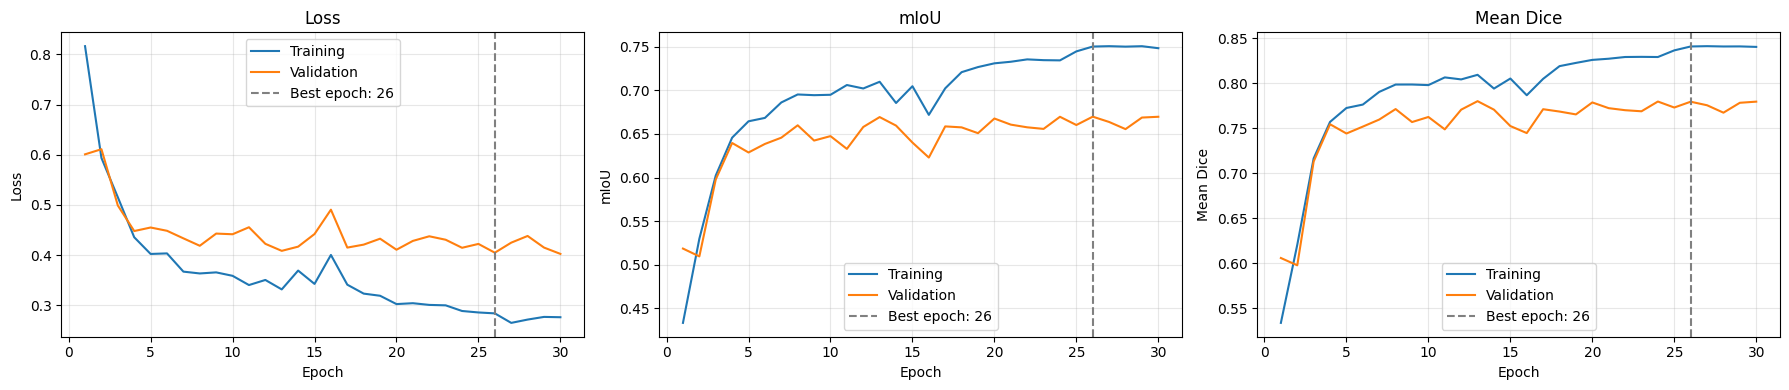


Best-checkpoint validation results:


,Class,IoU,Dice
0,Sea,0.9598,0.9795
1,Oil spill,0.5407,0.7019
2,Look-alike,0.5800,0.7342
3,Ships,0.3592,0.5286
4,Land,0.9092,0.9525



Curves and tables saved.


In [12]:
import pandas as pd
import matplotlib.pyplot as plt

# Use ALL 30 epochs for the curves
with (OUTPUT_DIR / "history.json").open() as file:
    full_history = json.load(file)

history_df = pd.DataFrame(full_history)

# Load the checkpoint selected using validation mIoU
best_checkpoint = torch.load(
    OUTPUT_DIR / "best_checkpoint.pth",
    map_location="cpu",
    weights_only=False
)

model.load_state_dict(best_checkpoint["model_state_dict"])
model.eval()

selected_epoch = best_checkpoint["epoch"]
best_scores = best_checkpoint["val_scores"]

print("Selected epoch:", selected_epoch)
print(f"Validation mIoU: {best_scores['miou']:.4f}")
print(f"Validation mean Dice: {best_scores['mean_dice']:.4f}")
print(f"Validation pixel accuracy: {best_scores['pixel_accuracy']:.4f}")
print(
    "Total logged epoch time:",
    f"{history_df['seconds'].sum() / 60:.2f} minutes"
)

# Training history
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

plot_settings = [
    ("loss", "Loss"),
    ("miou", "mIoU"),
    ("mean_dice", "Mean Dice")
]

for ax, (key, title) in zip(axes, plot_settings):
    ax.plot(
        history_df["epoch"], history_df[f"train_{key}"],
        label="Training"
    )
    ax.plot(
        history_df["epoch"], history_df[f"val_{key}"],
        label="Validation"
    )
    ax.axvline(
        selected_epoch, color="gray",
        linestyle="--", label=f"Best epoch: {selected_epoch}"
    )
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "training_curves.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

# Per-class VALIDATION results from the selected checkpoint
class_results = pd.DataFrame({
    "Class": CLASS_NAMES,
    "IoU": best_scores["per_class_iou"],
    "Dice": best_scores["per_class_dice"]
})

print("\nBest-checkpoint validation results:")
display(class_results.round(4))

history_df.to_csv(OUTPUT_DIR / "history.csv", index=False)
class_results.to_csv(
    OUTPUT_DIR / "validation_per_class.csv", index=False
)

print("\nCurves and tables saved.")

### 12. Validation prediction examples

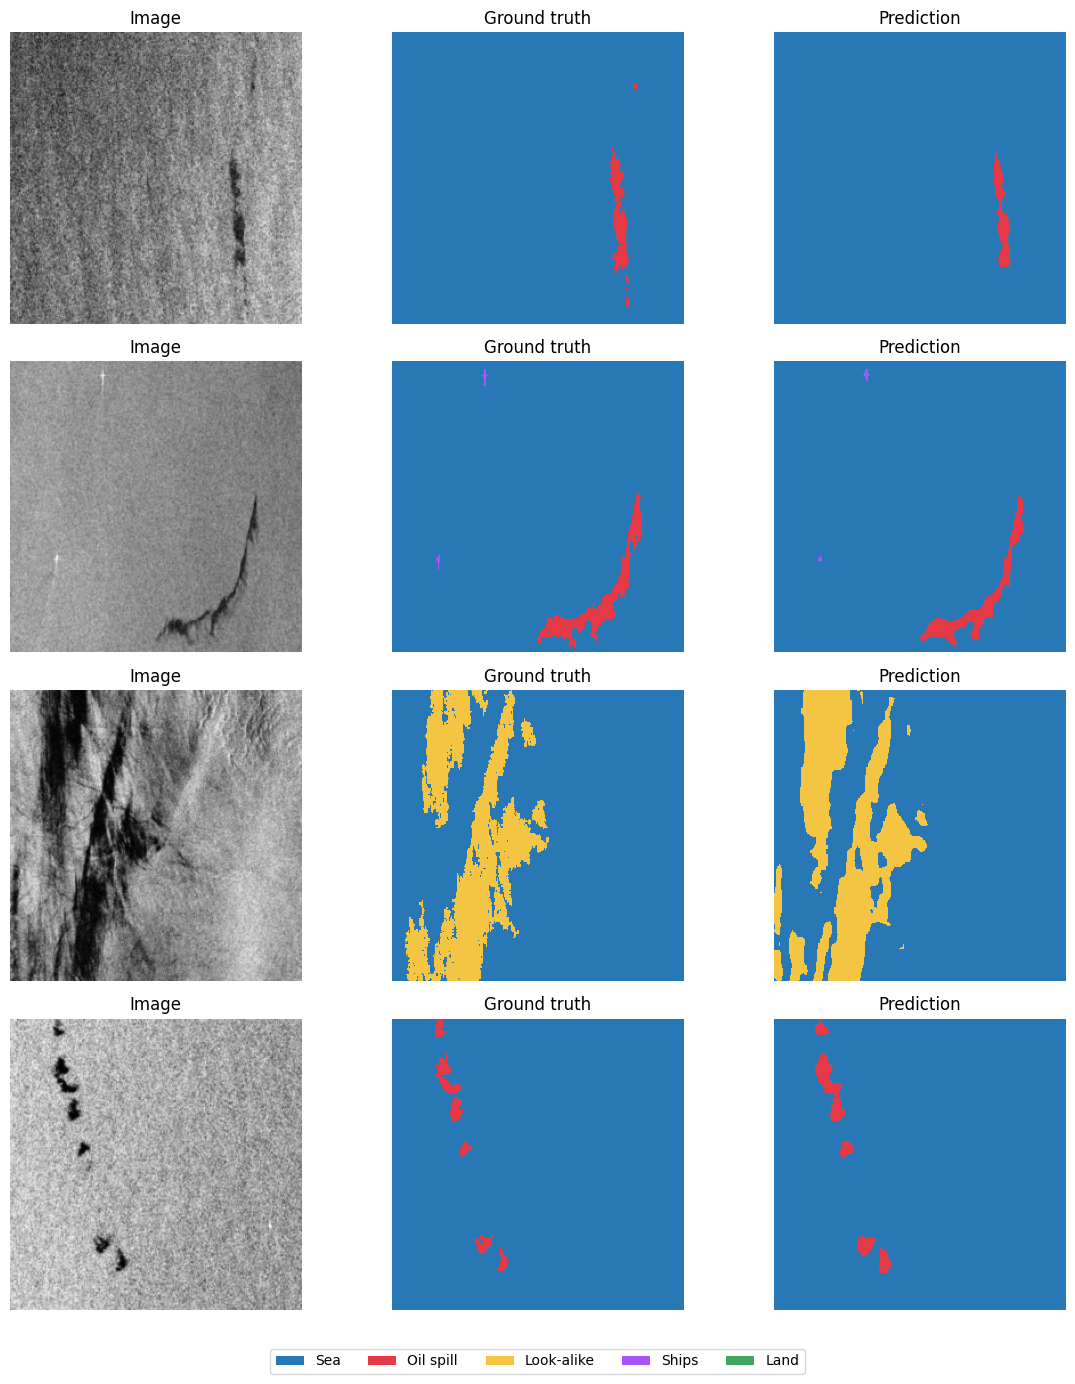

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

# Fixed colors for class IDs 0–4
colors = ["#2878B5", "#E63946", "#F4C542", "#A855F7", "#42A55F"]
class_cmap = ListedColormap(colors)
class_norm = BoundaryNorm(np.arange(NUM_CLASSES + 1) - 0.5, NUM_CLASSES)

images, masks = next(iter(val_loader))
n = min(4, images.size(0))

model.eval()
with torch.no_grad():
    predictions = model(images[:n].to(device)).argmax(dim=1).cpu()

# Undo ImageNet normalization for display only
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
visible_images = (
    images[:n].detach().cpu() * std + mean
).clamp(0, 1)

fig, axes = plt.subplots(
    n, 3, figsize=(12, 3.5 * n), squeeze=False
)

for i in range(n):
    axes[i, 0].imshow(visible_images[i].permute(1, 2, 0))
    axes[i, 1].imshow(
        masks[i].cpu(), cmap=class_cmap, norm=class_norm,
        interpolation="nearest"
    )
    axes[i, 2].imshow(
        predictions[i], cmap=class_cmap, norm=class_norm,
        interpolation="nearest"
    )

    for j, title in enumerate(["Image", "Ground truth", "Prediction"]):
        axes[i, j].set_title(title)
        axes[i, j].axis("off")

legend = [
    Patch(facecolor=color, label=name)
    for color, name in zip(colors, CLASS_NAMES)
]
fig.legend(
    handles=legend, loc="lower center",
    ncol=NUM_CLASSES, bbox_to_anchor=(0.5, 0.01)
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig(
    OUTPUT_DIR / "validation_predictions.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

### 13. Evaluate **once** on the official test set (ignore unknown test mask colors)

The test set is never used for choosing the best epoch. The evaluation follows Member 3's final test cell exactly, including its 255 ignore policy.

Official test:   0%|          | 0/14 [00:00<?, ?it/s]

Best epoch selected by validation: 26
TEST mIoU: 0.6628
TEST mean Dice: 0.7724
TEST pixel accuracy: 0.9645
Ignored pixels at 256x256: 22


,Class,IoU,Dice
0,Sea,0.9630,0.9812
1,Oil spill,0.5252,0.6887
2,Look-alike,0.5724,0.7280
3,Ships,0.3432,0.5110
4,Land,0.9102,0.9530


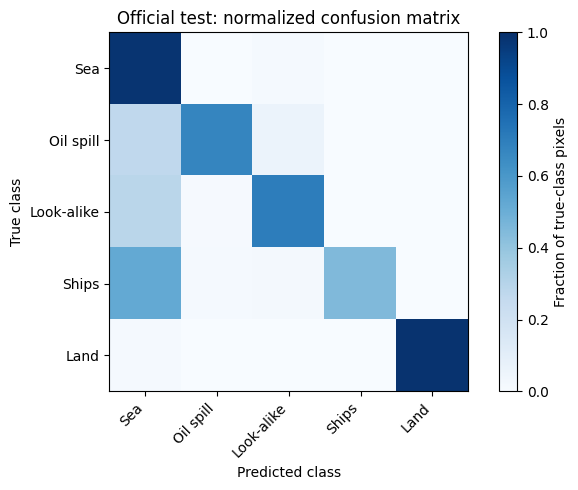

Official test results saved.


In [14]:
# Best checkpoint was selected using VALIDATION only in cell 11.
model.load_state_dict(best_checkpoint['model_state_dict'])
model.eval()
confusion = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.int64)
ignored_pixels = 0
evaluated_pixels = 0
with torch.no_grad():
    for batch_images, batch_masks in tqdm(test_loader, desc='Official test'):
        predictions = model(batch_images.to(device)).argmax(dim=1).cpu()
        valid = batch_masks != IGNORE_ID
        ignored_pixels += (~valid).sum().item()
        evaluated_pixels += valid.sum().item()
        confusion += batch_confusion_matrix(batch_masks[valid], predictions[valid])

test_scores = metrics_from_confusion(confusion)
print('Best epoch selected by validation:', best_checkpoint['epoch'])
print('TEST mIoU:', round(test_scores['miou'], 4))
print('TEST mean Dice:', round(test_scores['mean_dice'], 4))
print('TEST pixel accuracy:', round(test_scores['pixel_accuracy'], 4))
print('Ignored pixels at 256x256:', ignored_pixels)

test_results = pd.DataFrame({'Class': CLASS_NAMES,
                             'IoU': test_scores['per_class_iou'],
                             'Dice': test_scores['per_class_dice']})
display(test_results.round(4))
test_results.to_csv(OUTPUT_DIR/'test_per_class.csv', index=False)
pd.DataFrame(confusion.numpy(), index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
    OUTPUT_DIR/'test_confusion_matrix.csv')

def json_safe(v):
    if isinstance(v,list): return [x if np.isfinite(x) else None for x in v]
    return v
saved_scores = {k: json_safe(v) for k,v in test_scores.items()}
with (OUTPUT_DIR/'test_metrics.json').open('w') as f:
    json.dump({'selected_epoch': best_checkpoint['epoch'],
               'evaluation_resolution': list(IMAGE_SIZE),
               'unknown_color_policy': 'exclude from evaluation',
               'ignored_pixels': ignored_pixels,
               'evaluated_pixels': evaluated_pixels,
               'metrics': saved_scores}, f, indent=2, allow_nan=False)

fig, ax = plt.subplots(figsize=(7,5))
cm_float = confusion.numpy().astype(float)
den = cm_float.sum(axis=1, keepdims=True)
cm_norm = np.divide(cm_float, den, out=np.zeros_like(cm_float), where=den>0)
im = ax.imshow(cm_norm, vmin=0, vmax=1, cmap='Blues')
ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45, ha='right')
ax.set_yticks(range(NUM_CLASSES), CLASS_NAMES)
ax.set_xlabel('Predicted class'); ax.set_ylabel('True class')
ax.set_title('Official test: normalized confusion matrix')
fig.colorbar(im, ax=ax, label='Fraction of true-class pixels')
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'test_confusion_matrix.png', dpi=200, bbox_inches='tight')
plt.show()
print('Official test results saved.')

### 14. Official-test visual predictions (after final evaluation)

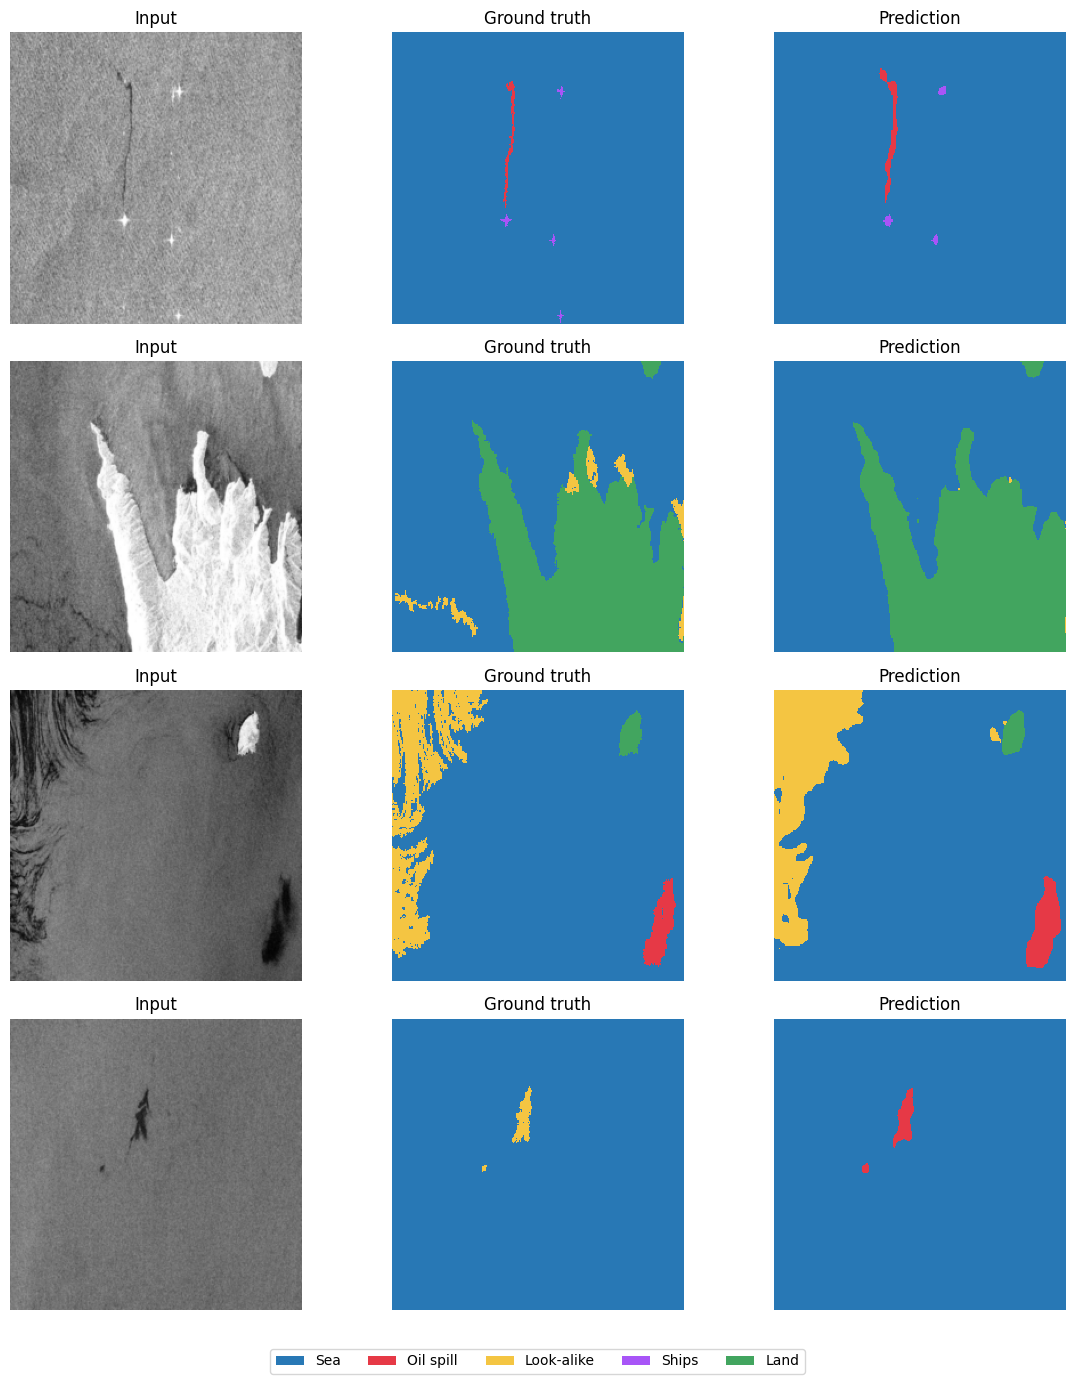

In [15]:
colors = ['#2878B5', '#E63946', '#F4C542', '#A855F7', '#42A55F']
class_cmap = ListedColormap(colors)
class_norm = BoundaryNorm(np.arange(NUM_CLASSES+1)-0.5, NUM_CLASSES)
images, masks = next(iter(test_loader))
n = min(4, len(images))
model.eval()
with torch.no_grad():
    preds = model(images[:n].to(device)).argmax(dim=1).cpu()
mean = torch.tensor([0.485,0.456,0.406]).view(3,1,1)
std = torch.tensor([0.229,0.224,0.225]).view(3,1,1)
visible = (images[:n]*std+mean).clamp(0,1)
fig, axes = plt.subplots(n,3,figsize=(12,3.5*n),squeeze=False)
for i in range(n):
    axes[i,0].imshow(visible[i].permute(1,2,0))
    axes[i,1].imshow(np.ma.masked_equal(masks[i].numpy(),IGNORE_ID),
                     cmap=class_cmap,norm=class_norm,interpolation='nearest')
    axes[i,2].imshow(preds[i].numpy(),cmap=class_cmap,norm=class_norm,
                     interpolation='nearest')
    for j,title in enumerate(('Input','Ground truth','Prediction')):
        axes[i,j].set_title(title);axes[i,j].axis('off')
fig.legend(handles=[Patch(facecolor=c,label=n) for c,n in zip(colors,CLASS_NAMES)],
           loc='lower center',ncol=NUM_CLASSES,bbox_to_anchor=(0.5,0.01))
plt.tight_layout(rect=[0,0.05,1,1])
plt.savefig(OUTPUT_DIR/'test_predictions.png',dpi=200,bbox_inches='tight')
plt.show()

### 15. Package all outputs; download the ZIP and keep the saved Kaggle Notebook version

**Note:** If the notebook is re-run from the top in a fresh Kaggle session, it trains afresh; the checkpoints saved in the previous version don't automatically become `/kaggle/working` in the new session.

In [16]:
required_files = ['best_checkpoint.pth','last_checkpoint.pth','config.json',
                  'split.json','history.json','history.csv',
                  'training_curves.png','validation_predictions.png',
                  'test_metrics.json','test_per_class.csv',
                  'test_confusion_matrix.csv','test_confusion_matrix.png',
                  'test_predictions.png']
missing = [name for name in required_files if not (OUTPUT_DIR/name).is_file()]
assert not missing, 'Missing output files: '+str(missing)
archive_path = shutil.make_archive(str(OUTPUT_DIR)+'_FINAL','zip',root_dir=OUTPUT_DIR)
print('SUCCESS — your complete experiment archive:', archive_path)
print('Best epoch:', best_epoch, '| Best validation mIoU:', round(best_miou,4))
print('Test mIoU:', round(test_scores['miou'],4),
      '| Test mean Dice:', round(test_scores['mean_dice'],4))
from IPython.display import FileLink, display
try:
    display(FileLink(archive_path))
except Exception:
    print('Download the ZIP from Kaggle > Output tab.')

SUCCESS — your complete experiment archive: /kaggle/working/deeplab_finetuned_exp2_FINAL.zip
Best epoch: 26 | Best validation mIoU: 0.6698
Test mIoU: 0.6628 | Test mean Dice: 0.7724


/kaggle/working/deeplab_finetuned_exp2_FINAL.zip

---
### What to submit / report

1. A link to the saved **Member 4** Kaggle notebook version and its training logs.
2. `deeplab_finetuned_exp2_FINAL.zip`, including best/last checkpoints, config, split, history, per-class IoU/Dice, confusion matrix, and predictions.
3. A comparison with **Member 3's own frozen experiment** at matching image resolution, class map, and evaluation protocol.

Member 3's previously reported frozen test results for reference (not generated by this notebook): **mIoU 0.6509**, **mean Dice 0.7616**, **pixel accuracy 0.9649**. Do not type those values into Member 4 output as if they were results of this run.